## Single-column RCE model

This notebook contains the structure for your RCE model. There are key functions to complete and all visulizations are left to your design.

This RCE model will follow the Manabe and Strickler 1964 approach.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### Main settings and parameters

In [2]:
# Experiment selection:
# 'convective_mode_variation' runs the sweep of equilibrium modes
# 'tau0_variation' runs a sweep of surface optical thickness values (tau0)
select_experiment = 'convective_mode_variation'

# Experiment-dependent settings:
convective_mode_sweep = ["radiative", "dry", "moist"] # the three equilibrium modes to sweep over
tau0_sweep = [0.1, 1, 2, 4, 6] # surface optical depth values to sweep over

#### Parameters

In [3]:
# Physical constants
g = 9.81                  # m/s^2
Rd = 287.0                # J/(kg K)
Rv = 461.0                # J/(kg K)
cp = 1004.0               # J/(kg K)
Lv = 2.5e6                # J/kg
sigma = 5.670374419e-8    # Stefan-Boltzmann
CtoK = 273.15             # Celsius to Kelvin

# Model parameters
Nz = 60                   # number of atmospheric layers
p_surf = 100000.0         # Pa
p_top  = 5000.0           # Pa
dt = 1000.0               # time step (s)
max_iter = 50000          # maximum number of iterations
T0_init = 250.0           # initial isothermal temperature profile (K)

# Radiative transfer settings
S0 = 1361.0                     # solar constant (W/m2)
albedo = 0.3                    # planetary albedo
S_in = S0 * (1 - albedo) / 4.0  # incoming solar radiation at TOA (W/m2)
relh0 = 0.8                     # assumed constant relative humidity for moist convective mixing
tau0 = 4.0                      # optical thickness at surface (tau(p_surf) = tau0)
tau_n = 2.0                     # exponent for tau(p) = tau0 * (p/p0)^n
mu_bar = 0.6                    # diffusivity factor for conversion from I to F

#### Helper functions

##### Create vertical grid

In [4]:
'''
This function sets up the vertical grid and initial T-profile for the RCE model.

Its structure is as follows:

             TOP
        -------------------  p_edges[Nz] = p_top
             p_mid[Nz-1]     layer Nz-1
        -------------------  p_edges[Nz-1]
               ...
        -------------------  p_edges[2]
             p_mid[1]        layer 1
        -------------------  p_edges[1]
             p_mid[0]        layer 0
        -------------------  p_edges[0] = p_surf
            SURFACE

Index increases upward; pressure decreases upward.
Grid spacing is uniform in pressure.

Temperature is defined at layer midpoints.
Optical depth tau is defined at edges and decreases upward
(assuming tau0 > 0 and tau_n > 0).

For each layer k:
  p_mid[k] = 0.5 * (p_edges[k] + p_edges[k+1])
  dp[k]    = p_edges[k] - p_edges[k+1] > 0
  dtau[k]  = tau_edges[k] - tau_edges[k+1] > 0

'''
def get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init):

    # Vertical grid (pressure edges and midpoints)
    p_edges = np.linspace(p_surf, p_top, Nz+1)    # edges (Pa), bottom --> top
    p_mid = 0.5*(p_edges[:-1] + p_edges[1:])      # pressure at layer mid-points
    dp = p_edges[:-1] - p_edges[1:]               # dp of each layer (positive)

    # Optical depth at layer edges
    tau_edges = tau0 * (p_edges / p_surf)**tau_n
    dtau = tau_edges[:-1] - tau_edges[1:]

    # Initial isothermal temperature profile (defined at layer midpoints)
    T_init = np.repeat(T0_init, Nz) # K

    grid = {}
    grid['p_edges'] = p_edges
    grid['p_mid'] = p_mid
    grid['dp'] = dp
    grid['tau_edges'] = tau_edges
    grid['dtau'] = dtau
    grid['T_init'] = T_init

    return grid

##### Thermodynamic functions

In [5]:
# saturation vapor pressure (Magnus)
def es_sat(Tk):
    Tc = Tk - 273.15
    return 610.94 * np.exp(17.625 * Tc / (Tc + 243.04))

# saturation mixing ratio from saturation vapor pressure
def qsat(Tk, p):
    eps = Rd / Rv
    e_s = es_sat(Tk)
    return eps * e_s / (p - (1-eps)*e_s)

#Can use DALR in units of K/pa, with nothing else changed, and will get K/pa
def moist_lapse_rate_K_per_m(DALR, Tk, p, RH=1.0):
    """
    Moist-adiabatic lapse rate with saturation mixing ratio scaled by a given RH.
    DALR input is the dry adiabatic lapse rate, provided either in K/m or K/Pa,
    which determines the units of the returned lapse rate.
    """
    q = qsat(Tk, p) * RH
    numerator = DALR * (1.0 + (Lv * q) / (Rd * Tk))
    denominator = 1.0 + (Lv**2 * q) / (cp * Rv * Tk**2)
    return numerator / denominator

def calc_theta_prof(T_prof, p_mid):
    #Calculate potential temperature profile from temperature and pressure profiles.
    
    #Just returnt the potential temperature profile, for the dry mixing case.
    return T_prof * (100000.0 / p_mid) ** (Rd/cp)

def back_to_T_prof(theta_prof, p_mid):
    #Calculate temperature profile from potential temperature and pressure profiles.
    
    #Just return the temperature profile, for the theta prof
    return theta_prof * (p_mid / 100000.0) ** (Rd/cp)

In [6]:
#Create the grid of P and tau
vert_grid_dict = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)



In [7]:
vert_grid_dict.keys()

dict_keys(['p_edges', 'p_mid', 'dp', 'tau_edges', 'dtau', 'T_init'])

##### Radiative tranfer

In [8]:
def longwave_fluxes_and_heating(dps,Trs, epsilons, p_mids, T_inits):
    """

    Your function should conduct downward and upward flux sweeps and return the
    downward (F_down) and upward (F_up) fluxes at the layer edges, which you can
    then use to compute the net flux and heating rate for each layer.

    """
    #Start with constructing F_down.
    #This starts at the TOA, where we can assume there is no longwave flux coming down from space. 
    F_down = [0]#just prefill the 0 flux at TOA.

    F_0_down = 0

    for dp, Tr, epsilon, p, T in zip(dps[::-1], Trs[::-1], epsilons[::-1], p_mids[::-1], T_inits[::-1]):#[::-1] to start at TOA
        F_new_down = F_0_down * Tr + epsilon * sigma * T**4#Eqn from friday class
        F_down.append(F_new_down)#Append to list of downward fluxes

        F_0_down = F_new_down# Update the downward flux for the next layer

    #Now, lastly, reverse F_down so it matches the direction of the other arrays
    F_down = np.array(F_down)[::-1]

    #now, do F_up, which starts at surface. The surface has to emit the shortwave flux + longwave downward flux back up to maintain radiative equilibrium.
    F_0_up = S_in + F_down[0]#shortwave in plus down longwave flux at surface.

    #print("S_in = ", S_in)FIXME
    #print("F_down[0] = ", F_down[0])
    #print("F_down[-1] = ", F_down[-1])
    #print("F_0_up = ", F_0_up)

    F_up = [F_0_up]#surface edge filled

    #Do radiative transfer for each layer
    for dp, Tr, epsilon, p, T in zip(dps, Trs, epsilons, p_mids, T_inits):#.T to start at TOA
            F_new_up = F_0_up * Tr + epsilon * sigma * T**4#Eqn from friday class
            F_up.append(F_new_up)#Append to list of upward fluxes

            F_0_up = F_new_up# Update the upward flux for the next layer

    F_up = np.array(F_up)
    return F_down, F_up

In [9]:
"""
def find_equil_temp_profile(dps, Trs, epsilons, p_mids,T_inits, ds = 1):#Change of 1 second per step
    T_prof = T_inits.copy()#Make temp profile
    T_sfc = T_prof[0]#Initial surface temp

    #i = 0
    #while i < max_iter:
    #Get upward and downward fluxes from method
    F_down, F_up = longwave_fluxes_and_heating(dps,Trs, epsilons, p_mids, T_prof)
    #With upward and downward flixes, find F_net, where F_net = F_up - F_down
    F_net = F_up - F_down

    #From class, find dT/dt = -g/cp * dF_net/dP
    dF_net = np.diff(F_net) #Now defined at each mid
    
    dT_dt = -g/cp * dF_net/dps #Now defined at each mid
    
    #Change in T over time step ds
    dT = dT_dt * ds 

    #Update the temperature profile
    T_prof = T_prof + dT

    #Find T_sfc: remember equil is needed, 
    sfc_flux = F_up[0]
    T_sfc = (sfc_flux / sigma)**(1/4)#Boltzmann law

    i += 1

    return T_prof, T_sfc


"""
    

'\ndef find_equil_temp_profile(dps, Trs, epsilons, p_mids,T_inits, ds = 1):#Change of 1 second per step\n    T_prof = T_inits.copy()#Make temp profile\n    T_sfc = T_prof[0]#Initial surface temp\n\n    #i = 0\n    #while i < max_iter:\n    #Get upward and downward fluxes from method\n    F_down, F_up = longwave_fluxes_and_heating(dps,Trs, epsilons, p_mids, T_prof)\n    #With upward and downward flixes, find F_net, where F_net = F_up - F_down\n    F_net = F_up - F_down\n\n    #From class, find dT/dt = -g/cp * dF_net/dP\n    dF_net = np.diff(F_net) #Now defined at each mid\n    \n    dT_dt = -g/cp * dF_net/dps #Now defined at each mid\n    \n    #Change in T over time step ds\n    dT = dT_dt * ds \n\n    #Update the temperature profile\n    T_prof = T_prof + dT\n\n    #Find T_sfc: remember equil is needed, \n    sfc_flux = F_up[0]\n    T_sfc = (sfc_flux / sigma)**(1/4)#Boltzmann law\n\n    i += 1\n\n    return T_prof, T_sfc\n\n\n'

##### Convective adjustment

In [10]:
def convective_adjustment(T_prof, p_mids, dps, LR_prof):
    """
    Adjust temperature profile for convective instability. The approach is to compare
    the T-change between adjacent layers, and if that lapse rate exceeds the dry or
    reference lapse rate, "mix" the two layers by adjusting both layers toward the
    reference lapse rate.

    "Sweeps" refers to the number of times to loop through the vertical profile and
    check for instability. If any mixing occurs, the sweeps continue until either the
    instability is removed or "max_sweeps" is reached. I have max_sweeps set to 10,
    but you can try other values.
    
    """
    max_sweeps = 10
    for sweep in range(max_sweeps):
        changed = False
        
        #Compute what the temp profile should be if the lapse rate were obeyed.
        #dp_mids = np.diff(p_mids)
        LR_prof_temp = LR_prof * dps #Convert from dK/dPa to just dK
        #dT_crit = dps * (LR_prof[:-1] + LR_prof[1:]) / 2  # Average lapse rate for critical temperature difference
        LR_prof_temp_short = LR_prof_temp[:-1]
        
        #T_expected = np.concatenate([np.array([T_prof[0]]), T_prof[0] - np.cumsum(LR_prof_temp)])

        #Calculate the 
        #T_diffs_LR = np.diff(T_expected)

        T_diffs_actual = np.diff(T_prof)

        #is_this_negative = T_diffs_actual - T_diffs_LR

        #is_this_negative_boolean = is_this_negative < 0
        is_this_negative_boolean = T_diffs_actual < -LR_prof_temp_short

        #Actually imma just theta this just in case.
        #theta_prof = calc_theta_prof(T_prof, p_mids)

        for l in range(len(is_this_negative_boolean)):

            if is_this_negative_boolean[l] == True:
                #theta_new = (theta_prof[l] + theta_prof[l+1])/2
                #theta_prof[l] = theta_new
                #theta_prof[l+1] = theta_new#This is just a simple average of air temp... need to check if i need to theta this FIXME
                T_new = T_prof[l] + T_prof[l+1]
                T_prof[l] = (T_new + LR_prof_temp_short[l]) / 2
                T_prof[l+1] = (T_new - LR_prof_temp_short[l]) / 2

                changed = True#booly boy

        #T_prof = back_to_T_prof(theta_prof, p_mids)#Convert back to T_prof
          

        # If no mixing occurred, end convective sweeps
        if not changed:
            break
    return T_prof

##### Save model state at a given time step

In [11]:
def save_singlelev_step(history, T_surf, T0, OLR, TOA_net):
    history["T_surf"].append(T_surf)
    history["T0"].append(T0)
    history["OLR"].append(OLR)
    history["TOA_net"].append(TOA_net)
    return history

def save_profiles_step(history, T, F_up_edges, F_down_edges, dTdt_rad, dTdt_conv):
    history["T"].append(T.copy())
    history["F_up"].append(F_up_edges)
    history["F_down"].append(F_down_edges)
    history["dTdt_rad"].append(dTdt_rad)
    history["dTdt_conv"].append(dTdt_conv)
    return history

#### Main RCE driver function

In [12]:
def run_rce_model(grid, convective_mode, ds = dt):#Just pull in the global var for time

    #### Initialize model state ############################

    #Now, to this grid, I can add transmissivity and epsilon (emissivity) for each layer.
    T = np.array(grid["T_init"]) #initial T profile
    dps = np.array(grid["dp"]) #P change
    p_mids = np.array(grid["p_mid"]) #P at grid mids
    dtaus = np.array(grid["dtau"]) #delta tau at grid mids
    Trs = np.exp(-1.66 * dtaus) #transmissivity eqn from class, provides vertical profile of transmissiivity 
    epsilons = 1 - Trs #Ems eqn from class, vert prof.

    # T-profile (K) at layer midpoints
    #T = grid['T_init'].copy() # using .copy() avoids modifying the original array

    # Initial surface temp from initial profile
    T_surf = T[0].copy()

    #### Set dictionary arrays for saving model state #################

    history = {
        "T_surf": [], "T0": [], "OLR": [], "TOA_net": [], # Single level stuff
        "T": [], "F_up": [], "F_down": [], "dTdt_rad": [], "dTdt_conv": [] # Nz stuff
        }
        # T_surf = surface temperature (K)
        # T0 = temperature of lowest atmospheric layer (K)
        # OLR = outgoing longwave radiation at TOA (W/m2)
        # TOA_net = net radiation at TOA (W/m2)
        # T = temperature profile (K) at layer midpoints
        # F_up = upward longwave flux (W/m2) at layer edges
        # F_down = downward longwave flux (W/m2) at layer edges
        # dTdt_rad = radiative heating rate (K/s) at layer midpoints
        # dTdt_conv = convective heating rate (K/s) at layer midpoints

    #### Run time loop #####################################

    current_time = 0 # in seconds
    for it in range(max_iter+1):

        # Save prior step temperature profile to get delta and check for convergence
        T_prior = T.copy()

        # Radiative solver
        #Get upward and downward fluxes from method
        F_down, F_up = longwave_fluxes_and_heating(dps, Trs, epsilons, p_mids, T)

        #With upward and downward flixes, find F_net, where F_net = F_up - F_down
        F_net = F_up - F_down

        # Radiative heating rate (K/s) from net flux
        #From class, find dT/dt = -g/cp * dF_net/dP
        dF_net = np.diff(F_net) #Now defined at each mid
        dTdt_rad = -g/cp * dF_net/dps #Now defined at each mid

        # Apply heating rate to temperature profile
        #Change in T over time step ds
        dT = dTdt_rad * ds
                
        #Update the temperature profile
        T = T + dT

        # Update surface temperature
        #Find T_sfc: remember equil is needed, 
        sfc_flux = F_up[0]
        T_surf = (sfc_flux / sigma)**(1/4)#Boltzmann law
                
        # Convective adjustment#FIXME not right now.

        # Save current temperature profile to calculate convective heating after convective mixing completes
        dTdt_conv = np.zeros_like(T)
        T_preconv = T.copy()

        if convective_mode == "dry":
            #need to calculate a profile of lapse rates, for the dry case first.
            #Calculate the dry adiabatic lapse rate profile
            LR_prof_dry = Rd * T / (cp * p_mids)

            T = convective_adjustment(T, p_mids, dps, LR_prof_dry)

            # After convective mixing completes, calculate convective heating tendency
            # as difference from pre-convective state
            dTdt_conv = (T - T_preconv)/ds

        if convective_mode == "moist":
            #need to calculate a profile of lapse rates, for the dry case first.
            #Calculate the dry adiabatic lapse rate profile
            LR_prof_dry = Rd * T / (cp * p_mids)
            LR_prof_moist = moist_lapse_rate_K_per_m(LR_prof_dry, T, p_mids, RH=relh0)

            T = convective_adjustment(T, p_mids, dps, LR_prof_moist)

            # After convective mixing completes, calculate convective heating tendency
            # as difference from pre-convective state
            dTdt_conv = (T - T_preconv)/ds

        current_time += dt

        ########## BOOKKEEPING FROM HERE ##########

        # What you need to do here:
        #   (1) Calculate OLR and TOA_net
        #   (2) Establish a way to check for equilibrium
        #   (3) Complete the write-outs, which are already drafted

        # Maximum temperature change from previous time step
        # This may or may not be useful to you
        maxdT = np.nanmax(np.abs(T - T_prior))

        # Kill if NaN detected
        if np.isnan(maxdT):
            print(f"NaN detected — stopping: it {it:5d} maxdT={maxdT:.5e} K")
            break

        # Save single-level stuff every time step
        OLR = F_up[-1]
        TOA_net = S_in - OLR
        save_singlelev_step(history, T_surf, T[0], OLR, TOA_net)

        # # Write out some stats every nreadstat time step
        nread_stat = 2500
        if it % nread_stat == 0:
            print(f"it {it:5d} maxdT={maxdT:.5e} K, T_surf={T_surf-273:.3f} C, T0={T[0]-273:.3f} C, OLR={OLR:.2f} W/m2, TOA_net={TOA_net:.2f} W/m2")

        #Save profiles every nprof time step
        nprof = 2500
        if it % nprof == 0:
            save_profiles_step(history, T, F_up, F_down, dTdt_rad, dTdt_conv)

        # Check for equilibrium; break loop if reached
        #FIXME check this
        if TOA_net < 1e-3 and maxdT < 1e-3:
            print(f"Equilibrium reached at it {it:5d} maxdT={maxdT:.5e} K, T_surf={T_surf-273:.3f} C, T0={T[0]-273:.3f} C, OLR={OLR:.2f} W/m2, TOA_net={TOA_net:.2f} W/m2")
            break

    return history

In [13]:
#plotting code here: It needs to be defined first.
def make_plots(history_save, p_mids):
    #Make a temperature profile plot
    plt.plot(history_save['radiative']['T'][-1], p_mids/100, label='Radiative')
    plt.plot(history_save['dry']['T'][-1], p_mids/100, label='Dry Convective')
    plt.plot(history_save['moist']['T'][-1], p_mids/100, label='Moist Convective')

    plt.ylim(p_mids[0]/100, p_mids[-1]/100)
    plt.grid()

    plt.title('Temperature Profile, Non Skew-T')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (hPa)')
    plt.legend()
    plt.show()

    #Make a time series of the TOA net radiation for each convective mode
    plt.plot(history_save['radiative']['TOA_net'], label='Radiative')
    plt.plot(history_save['dry']['TOA_net'], label='Dry Convective')
    plt.plot(history_save['moist']['TOA_net'], label='Moist Convective')
    plt.grid()
    plt.title('TOA Net Radiation Time Series')
    plt.xlabel('Time Step')
    plt.ylabel('TOA Net Radiation (W/m^2)')
    plt.legend()
    plt.show()

    #TODO skew T

    

In [18]:
#plotting code here: It needs to be defined first.
def make_plots_tau(history_save, p_mids):
    #Make a temperature profile plot
    plt.plot(history_save['tau0=0.1']['T'][-1], p_mids/100, label='tau0=0.1')
    plt.plot(history_save['tau0=1.0']['T'][-1], p_mids/100, label='tau0=1')
    plt.plot(history_save['tau0=2.0']['T'][-1], p_mids/100, label='tau0=2')
    plt.plot(history_save['tau0=4.0']['T'][-1], p_mids/100, label='tau0=4')
    plt.plot(history_save['tau0=6.0']['T'][-1], p_mids/100, label='tau0=6')

    plt.ylim(p_mids[0]/100, p_mids[-1]/100)
    plt.grid()

    plt.title('Temperature Profile, Non Skew-T')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (hPa)')
    plt.legend()
    plt.show()

    #Make a time series of the TOA net radiation for each convective mode
    plt.plot(history_save['tau0=0.1']['TOA_net'], label='tau0=0.1')
    plt.plot(history_save['tau0=1.0']['TOA_net'], label='tau0=1')
    plt.plot(history_save['tau0=2.0']['TOA_net'], label='tau0=2')
    plt.plot(history_save['tau0=4.0']['TOA_net'], label='tau0=4')
    plt.plot(history_save['tau0=6.0']['TOA_net'], label='tau0=6')
    plt.grid()
    plt.title('TOA Net Radiation Time Series')
    plt.xlabel('Time Step')
    plt.ylabel('TOA Net Radiation (W/m^2)')
    plt.legend()
    plt.show()

    #TODO skew T


### Run model

In [19]:
############## Set up the experiments ##############
def run_everything_i_guess(select_experiment):
    # Select the variable to loop over 'loop_var'
    # Set a list of experiment names 'exp_names'

    # This experiment loops over all equilibrium cases
    if select_experiment == 'convective_mode_variation':
        loop_var = convective_mode_sweep
        exp_names = loop_var # Names are just the equilibrium mode names

    # This experiment loops over tau cases
    elif select_experiment == 'tau0_variation':
        loop_var = tau0_sweep
        exp_names = [f'tau0={tau0 :.1f}' for tau0 in loop_var] # Name them based on actual tau values


    ############## Loop over the experiments ##############

    # Save history from each run and add to dictionary where keys = experiment names
    history_save = {}

    # Here, iexp is the index of the experiment, isetting is the value of the variable
    # being looped over (either convective mode or tau0)
    for iexp, isetting in enumerate(loop_var):

            exp_name = exp_names[iexp]

            if select_experiment == 'convective_mode_variation':
                tau0 = 4.0
                convective_mode = isetting
            elif select_experiment == 'tau0_variation':
                tau0 = isetting
                convective_mode = "moist"

            # run GRID to compute new optical depth
            grid = get_grid_tau(Nz, p_surf, p_top, tau0, tau_n, T0_init)

            # --- run model ---
            print()
            print("Starting RCE run for '{}".format(exp_name)+"'")

            history_save[exp_name] = run_rce_model(grid, convective_mode)

    if select_experiment == 'convective_mode_variation':
        make_plots(history_save, grid['p_mid'])
    elif select_experiment == 'tau0_variation':
        make_plots_tau(history_save, grid['p_mid'])



Starting RCE run for 'radiative'
it     0 maxdT=2.75974e-01 K, T_surf=27.013 C, T0=-22.724 C, OLR=221.82 W/m2, TOA_net=16.36 W/m2
it  2500 maxdT=8.66664e-03 K, T_surf=83.454 C, T0=69.642 C, OLR=186.34 W/m2, TOA_net=51.83 W/m2
it  5000 maxdT=2.86817e-03 K, T_surf=90.685 C, T0=77.925 C, OLR=217.21 W/m2, TOA_net=20.96 W/m2
it  7500 maxdT=1.24360e-03 K, T_surf=92.725 C, T0=80.235 C, OLR=230.56 W/m2, TOA_net=7.61 W/m2
it 10000 maxdT=5.61642e-04 K, T_surf=93.378 C, T0=80.971 C, OLR=235.43 W/m2, TOA_net=2.74 W/m2
it 12500 maxdT=2.66807e-04 K, T_surf=93.597 C, T0=81.218 C, OLR=237.17 W/m2, TOA_net=1.00 W/m2
it 15000 maxdT=1.25796e-04 K, T_surf=93.673 C, T0=81.304 C, OLR=237.80 W/m2, TOA_net=0.37 W/m2
it 17500 maxdT=6.46876e-05 K, T_surf=93.700 C, T0=81.334 C, OLR=238.03 W/m2, TOA_net=0.14 W/m2
it 20000 maxdT=3.21129e-05 K, T_surf=93.710 C, T0=81.345 C, OLR=238.12 W/m2, TOA_net=0.05 W/m2
it 22500 maxdT=1.54482e-05 K, T_surf=93.714 C, T0=81.349 C, OLR=238.15 W/m2, TOA_net=0.02 W/m2
it 25000 max

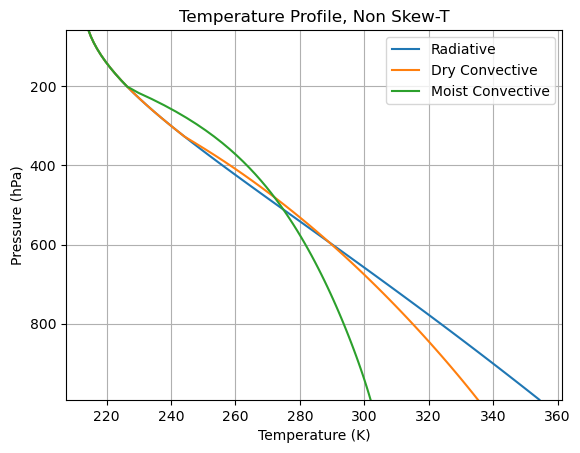

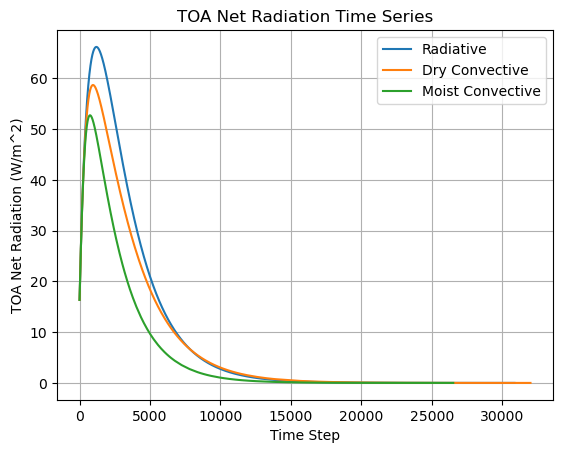

In [20]:
select_experiment = 'convective_mode_variation'
run_everything_i_guess(select_experiment)


Starting RCE run for 'tau0=0.1'
it     0 maxdT=4.43613e-03 K, T_surf=-9.834 C, T0=-23.004 C, OLR=264.27 W/m2, TOA_net=-26.10 W/m2
it  2500 maxdT=2.76972e-03 K, T_surf=-10.726 C, T0=-31.802 C, OLR=257.57 W/m2, TOA_net=-19.40 W/m2
it  5000 maxdT=1.90954e-03 K, T_surf=-11.326 C, T0=-37.427 C, OLR=253.08 W/m2, TOA_net=-14.91 W/m2
it  7500 maxdT=1.43919e-03 K, T_surf=-11.750 C, T0=-41.170 C, OLR=249.91 W/m2, TOA_net=-11.74 W/m2
it 10000 maxdT=1.14774e-03 K, T_surf=-12.061 C, T0=-43.731 C, OLR=247.59 W/m2, TOA_net=-9.42 W/m2
Equilibrium reached at it 11791 maxdT=9.99929e-04 K, T_surf=-12.235 C, T0=-45.073 C, OLR=246.29 W/m2, TOA_net=-8.12 W/m2

Starting RCE run for 'tau0=1.0'
it     0 maxdT=4.74537e-02 K, T_surf=19.908 C, T0=-22.953 C, OLR=258.90 W/m2, TOA_net=-20.72 W/m2
it  2500 maxdT=4.22477e-03 K, T_surf=24.229 C, T0=-1.116 C, OLR=253.11 W/m2, TOA_net=-14.94 W/m2
it  5000 maxdT=2.41006e-03 K, T_surf=23.770 C, T0=-1.526 C, OLR=246.77 W/m2, TOA_net=-8.60 W/m2
it  7500 maxdT=1.67689e-03 K,

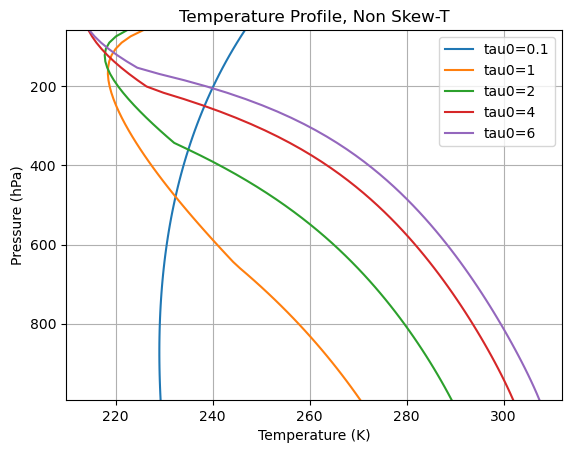

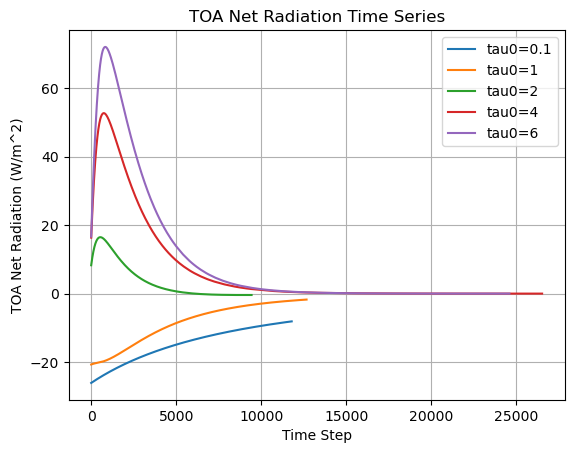

In [21]:
select_experiment = 'tau0_variation'
run_everything_i_guess(select_experiment)

## Plots

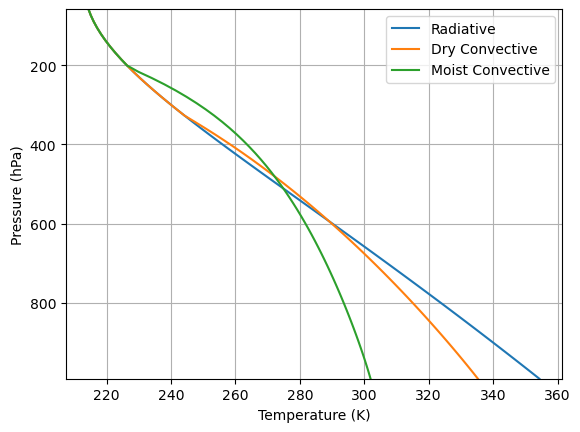

In [ ]:
def make_plots(history_save, p_mids):
    plt.plot(history_save['radiative']['T'][-1], p_mids/100, label='Radiative')
    plt.plot(history_save['dry']['T'][-1], p_mids/100, label='Dry Convective')
    plt.plot(history_save['moist']['T'][-1], p_mids/100, label='Moist Convective')

    plt.ylim(p_mids[0]/100, p_mids[-1]/100)
    plt.grid()

    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (hPa)')
    plt.legend()
    plt.show()

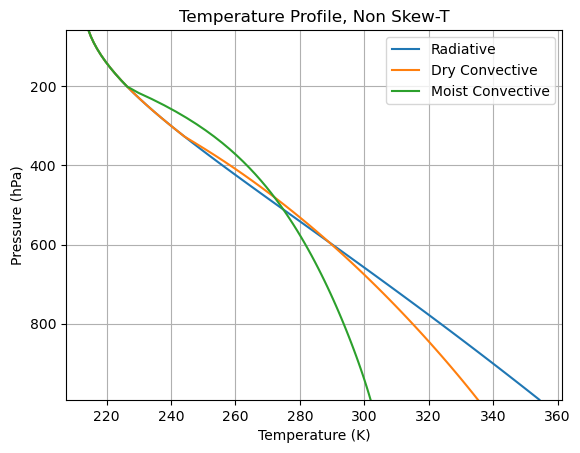

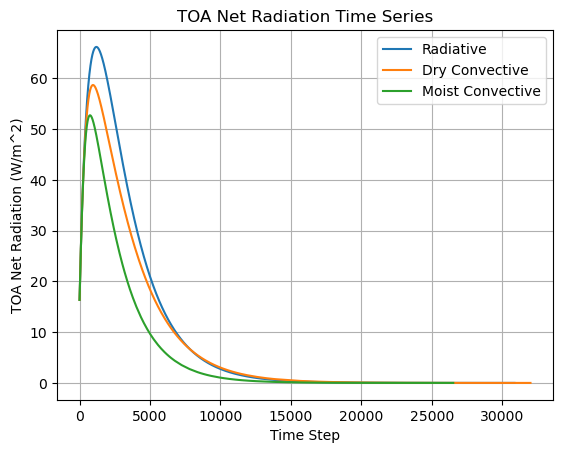

In [ ]:
make_plots(history_save, grid['p_mid'])